<a href="https://colab.research.google.com/github/emmagiometti/Glaciers_GlaciatedLandscapesA26/blob/main/RiverDischarge_GGL_Lane.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
## AI statement: code was generated with Claude.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [22]:
# 1. Read the data (sheet is named "river")
df = pd.read_csv("river.csv")

df.columns = df.columns.str.strip()

In [53]:
# 2. Convert year + fractional day-of-year to a datetime
# Assumes day 1.0 = 1 Jan 00:00. If your data uses 0-based days, remove the "- 1".
df["time"] = (
    pd.to_datetime(df["year"].astype(int).astype(str) + "-01-01")
    + pd.to_timedelta(df["frac_day"] - 1, unit="D")
).dt.round("min")   # removes floating-point noise (dt = 2 min)

# 3. Keep May to September only (Months 5 through 9, inclusive)
#df = df[df["time"].dt.month.between(5, 9)].set_index("time")

# 4. Resample to daily means (2-min data = ~220k points, which is slow to plot)
daily_water = df[["Qw", "Qw_lo", "Qw_hi"]].resample("1D").mean().reset_index()
daily_sed = df[["Qss", "Qss_lo", "Qss_hi"]].resample("1D").mean().reset_index()

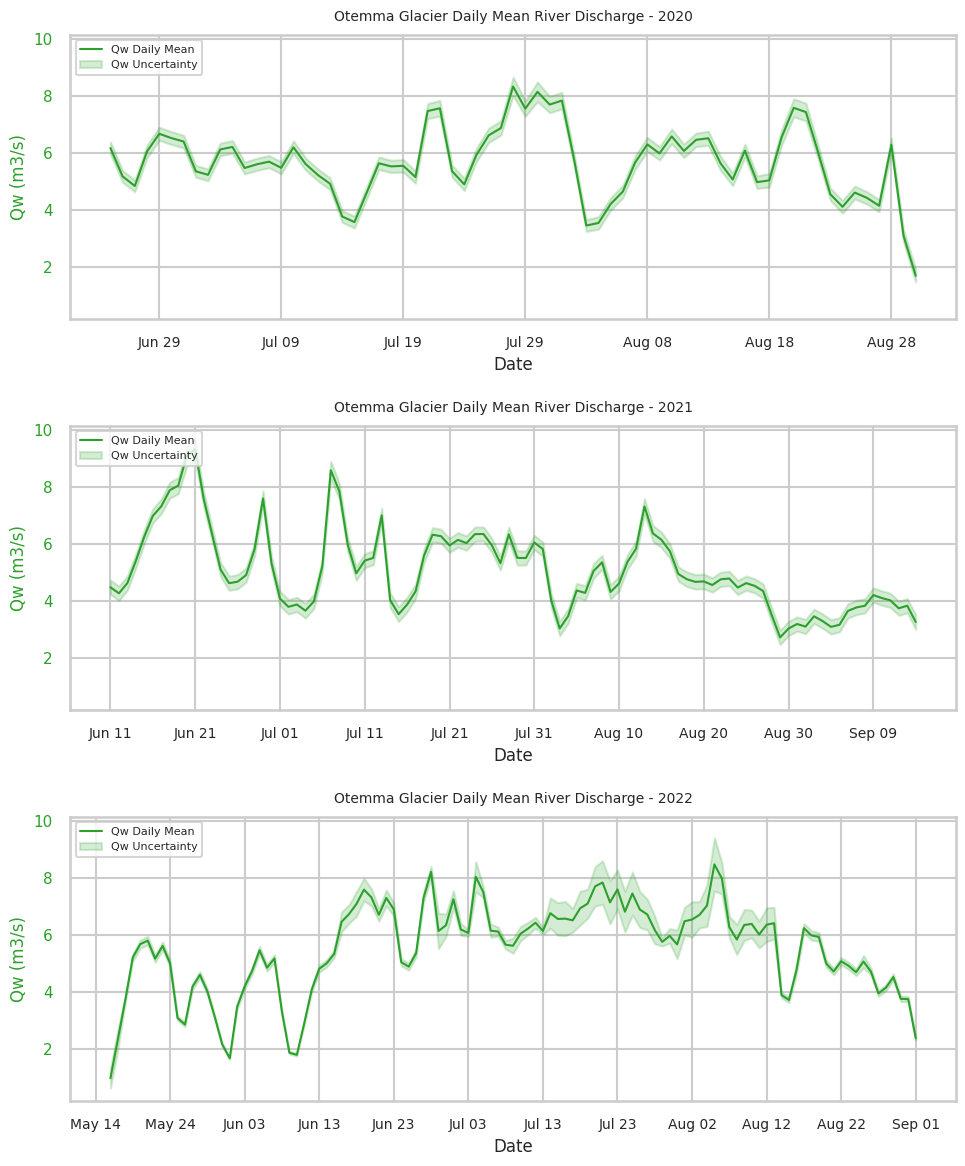

In [61]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Configure styling context with grid enabled
sns.set_theme(style="whitegrid", context="talk")

years = [2020, 2021, 2022]
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 12), sharey=True)

color_qw = "tab:green"

for i, year in enumerate(years):
    ax = axes[i]

    # Filter to specified year and crop empty NaN placeholder times
    year_data = daily_water[daily_water["time"].dt.year == year]
    active_year_data = year_data.dropna(subset=["Qw"])

    if active_year_data.empty:
        ax.text(0.5, 0.5, f"No active Qw data for {year}", ha="center", va="center")
        continue

    # Plot discharge line and confidence bounds
    sns.lineplot(
        data=active_year_data,
        x="time",
        y="Qw",
        ax=ax,
        linewidth=1.5,
        color=color_qw,
        label="Qw Daily Mean"
    )
    ax.fill_between(
        active_year_data["time"],
        active_year_data["Qw_lo"],
        active_year_data["Qw_hi"],
        color=color_qw,
        alpha=0.2,
        label="Qw Uncertainty"
    )

    # Configure details per subplot
    ax.set_title(f"Otemma Glacier Daily Mean River Discharge - {year}", fontsize=10, pad=10)
    ax.set_ylabel("Qw (m3/s)", color=color_qw, fontsize=12)
    ax.set_xlabel("", fontsize=12)
    ax.tick_params(axis='y', labelcolor=color_qw, labelsize=11)

    # Formatter & locator for date ticks
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=10))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.tick_params(axis='x', labelsize=10)
    ax.legend(loc="upper left", fontsize=8)

axes[1].set_xlabel("Date", fontsize=12)
axes[0].set_xlabel("Date", fontsize=12)
axes[-1].set_xlabel("Date", fontsize=12)
fig.tight_layout()
plt.show()

Notes from class discussion:
make a plot for instantaneous discharge
each years have very particular climates, so they will look different?

- consider seasonal timescale:
  - incoming solar radiation is what makes the glacier melt, not inherently "temperature".
  - in a warming world we make less snow and more rain -> no snow cover means can't make ice, more low-albedo ice exposed
  - why does it start to decline? because we are out of the solstice so solar radiation intensity is going down, but also because these are alpine glaciers and they are shaded by surrounding terrain
  -

Show the range: should be Qwlow - Qwhigh
- melt range is minimal because snow cover is high, buffers the effect of the incoming solar radiation and causes less melt because it is hard to get lots of melt with a snow covered surface.


the abnormal spike is a rain storm event

consider hydrological response time that causes a delay because water takes time to percolate through porous snow mass
when ice melts it runs off really fast compared to snow - explains why there is less attenuation (not as many spikes?)  

subglacial channels progressively move up-glacier, and the channels are very hydrologically efficient
if there is a good drainage network (subglacial channels) then the water will flow out much more quickly after melting, so the discharge will be lower at night, then during the day you will see bigger melt peaks and at night lower troughs


at end of summer season, water is coming out much more quickly, which means later in the season the discharge flux has time to lower so much, there is a much more rapid increase and decrease ?

any sharp rise and drop in sediment flux means some pocket of sediment was released, doesnt inherently show up on water flux

later in season you may see pockets released showing up later in the day because it takes longer for sediment pockets to reach outlet?

bedload starts riding after suspended load because bedload is hydrologically limited

spring flush event of suspended sediment being flushed out is because water input slightly floats glacier off bed, flushes out all the sediment

second spike in suspended sediment flux: storms that typically occur in afternoon when glacier already has a lot of water, when you add in more warm water on ice and into drainage system, it can really rinse out even more suspended sediment because the warm water can also slightly float the glacier

period of very high loads (day 200-210/220) is probably due to the efficiency of sediment evacuation - glacier hasnt got much snow left so the melt is very efficient and water is going everywhere in ice, mobilizing suspended sediment everywhere at the bed. supply rate is very high and then at end of season the sediment output declines shortly after water flux starts to decline, because there is not as much water to flush out sediment
suspended sediment is closely correlated to water discharge


BEDLOAD

seismometry measures bedload

- delay in influx because the channels havent gotten big enough yet to allow bedload to pass through
- channelization must occur before bedload can be exported
- onc echannelization gets going it runs quite strong, then goes down much earlier than suspended load
- why does bedload drop down so quickly, earlier than suspended sediment?
  - you run out of bedload to export
  channels are getting smaller as they expand up-glacier and they become too small to export bedload but not too small to export suspended load, so the channels cannot transport the bedload anymore


target for next week is to continue to work on plots and data?
if i want to also plot the range I have to calculate it from the highs and lows but not necessarily the best option



